# 02 Preprocessing

Everything between the raw fields and the network input, using the pipeline functions exactly as they
ran on Kaggle: physics channels, normalization, episode masks, the leak-free split, hour estimation
and the 20-channel input. CPU only.

In [1]:
import os
import sys
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

sys.path.insert(0, os.path.abspath('../src'))
import local

S = local.load_study()
C = S.C
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e4e3df', 'axes.spines.top': False, 'axes.spines.right': False})
ll = np.load(os.path.join(C.RAW, 'lat_long.npy'))
lat, lon = ll[..., 0], ll[..., 1]

device: cpu  backbone: resgru


## 1. Physics channels

- wind speed $\|\mathbf{u}_{10}\|$
- ventilation $V=\log(1+\mathrm{PBLH}\cdot\|\mathbf{u}_{10}\|)$: how easily the boundary layer clears; low $V$ is stagnant air
- advection $A=-(u\,\partial_x+v\,\partial_y)\log(1+C)$: the first-order transport of the PM2.5 field

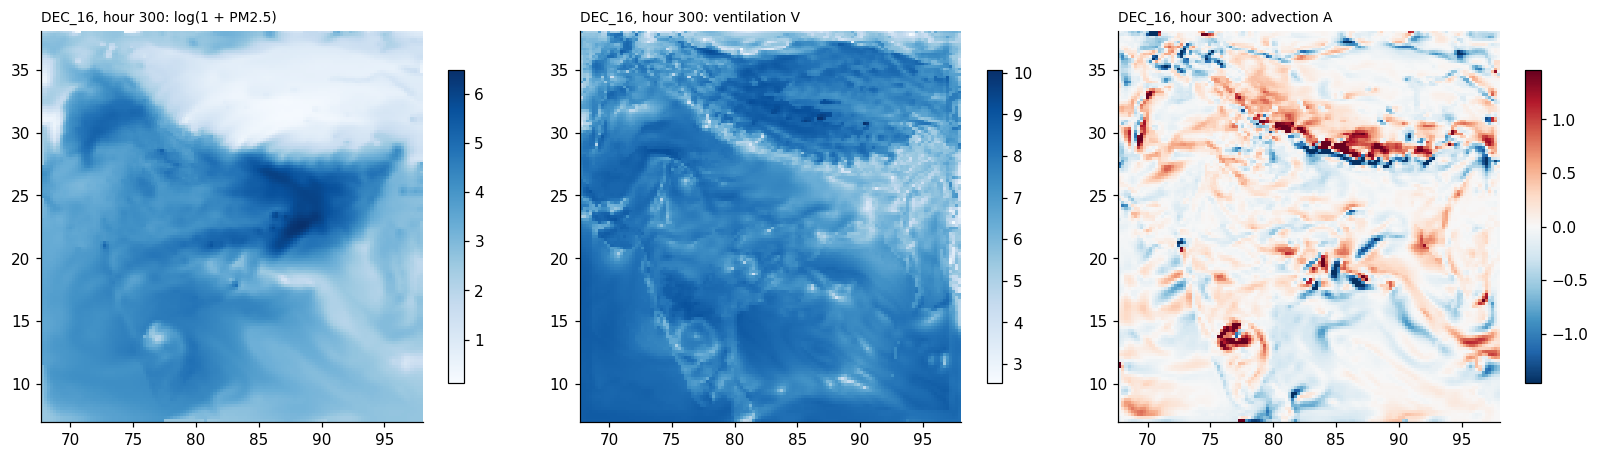

In [2]:
m, t = 'DEC_16', 300
arrs = {f: np.load(os.path.join(C.RAW, m, f'{f}.npy'))[t - 1:t + 1].astype(np.float32) for f in C.FEATS}
ws, vent, adv = S._derived(arrs)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
panels = ((np.log1p(arrs['cpm25'][1]), 'log(1 + PM2.5)', dict(cmap='Blues')),
          (vent[1], 'ventilation V', dict(cmap='Blues')),
          (adv[1], 'advection A', dict(cmap='RdBu_r', norm=TwoSlopeNorm(0, -np.percentile(np.abs(adv[1]), 99), np.percentile(np.abs(adv[1]), 99)))))
for a_, (z, title, kw) in zip(ax, panels):
    im = a_.pcolormesh(lon, lat, z, shading='auto', **kw)
    fig.colorbar(im, ax=a_, shrink=0.8); a_.set_title(f'{m}, hour {t}: {title}', loc='left', fontsize=9); a_.set_aspect('equal'); a_.grid(False)
plt.tight_layout(); plt.show()

## 2. Normalization statistics

Per-cell mean and standard deviation over the training part of each month only (never the validation
part), with the standard deviation floored at 0.1 times its median. The study reused the statistics of
the AFNO V4 run; here they are recomputed from the raw data and compared.

In [3]:
v4_stats = S.build_stats()  # loads data/interim/v4/stats.npz when present
work, v4dir = C.WORK, C.V4_DIR
C.WORK, C.V4_DIR = tempfile.mkdtemp(), None
fresh = S.build_stats()
C.WORK, C.V4_DIR = work, v4dir
for k in ('mean', 'std', 'clim24', 'dpm_std', 'sw_prof', 't2_prof'):
    print(f'{k:8s} shape {str(v4_stats[k].shape):18s} max |recomputed - V4| = {np.abs(fresh[k] - v4_stats[k]).max():.2e}')

computing normalization stats (train region only)...


mean     shape (12, 140, 124)     max |recomputed - V4| = 9.54e-07
std      shape (12, 140, 124)     max |recomputed - V4| = 6.62e-06
clim24   shape (24, 140, 124)     max |recomputed - V4| = 4.77e-07
dpm_std  shape (140, 124)         max |recomputed - V4| = 2.98e-08
sw_prof  shape (24,)              max |recomputed - V4| = 0.00e+00
t2_prof  shape (24,)              max |recomputed - V4| = 0.00e+00


## 3. Episode masks

An hour is an episode when the robust STL residual of that cell (24-hour period, computed on the whole
month) exceeds three standard deviations of the cell's residuals and the value exceeds 1 ug/m3. The
masks come from the AFNO V4 run; below, one cell is recomputed from scratch and compared.

APRIL_16: episode share 2.08% of cell-hours (2.20% train part, 1.52% validation part)
JULY_16: episode share 1.97% of cell-hours (2.19% train part, 0.98% validation part)
OCT_16: episode share 1.70% of cell-hours (1.49% train part, 2.66% validation part)
DEC_16: episode share 2.17% of cell-hours (2.15% train part, 2.28% validation part)


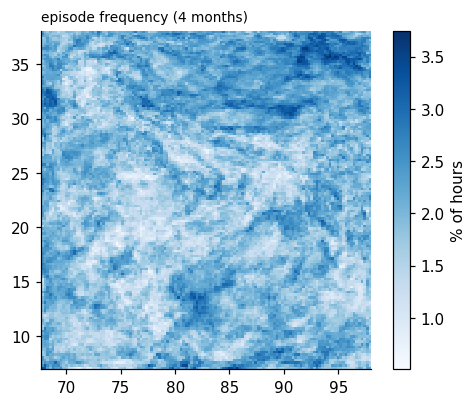

In [4]:
masks = {m: S.episode_masks(m)[0] for m in C.MONTHS}
for m, k in masks.items():
    vb = S.month_val_start(len(k))
    print(f'{m}: episode share {100 * k.mean():.2f}% of cell-hours ({100 * k[:vb].mean():.2f}% train part, {100 * k[vb:].mean():.2f}% validation part)')
freq = np.mean([k.mean(0) for k in masks.values()], axis=0)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.pcolormesh(lon, lat, 100 * freq, shading='auto', cmap='Blues'); fig.colorbar(im, ax=ax, label='% of hours')
ax.set_title('episode frequency (4 months)', loc='left', fontsize=9); ax.set_aspect('equal'); ax.grid(False); plt.show()

cell at 35.25 N, 94.26 E: 38 episode hours recomputed, mask identical to V4: True


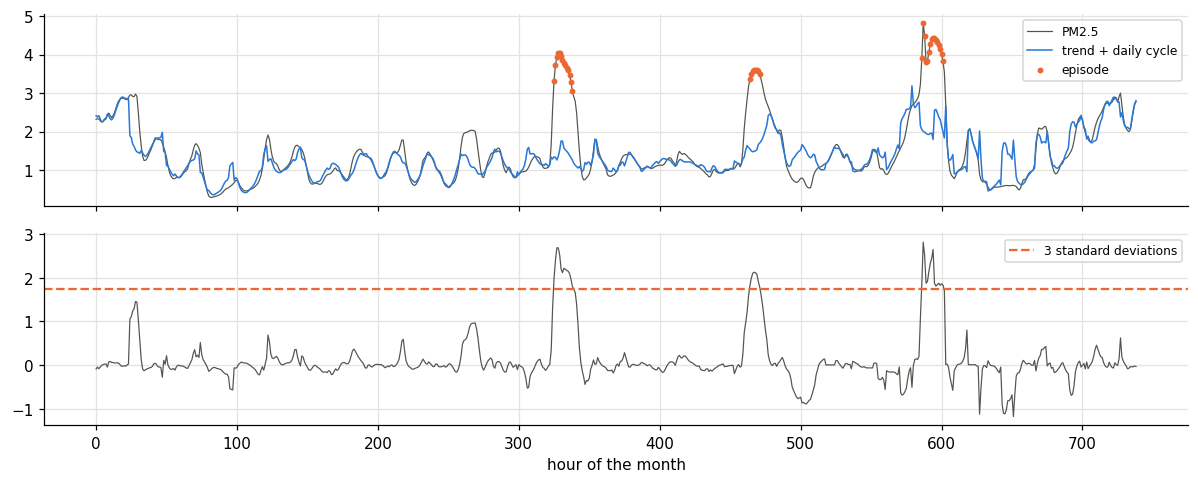

In [5]:
from statsmodels.tsa.seasonal import STL

m = 'DEC_16'
y = np.load(os.path.join(C.RAW, m, 'cpm25.npy')).astype(np.float32)
i, j = np.unravel_index(np.argmax(masks[m].sum(0)), masks[m].shape[1:])
ts = y[:, i, j].astype(np.float64)
res = STL(ts, period=24, robust=True).fit()
mine = (res.resid > 3 * (np.std(res.resid) + 1e-8)) & (ts > 1)
print(f'cell at {lat[i, j]:.2f} N, {lon[i, j]:.2f} E: {mine.sum()} episode hours recomputed, mask identical to V4: {bool((mine == masks[m][:, i, j].astype(bool)).all())}')
fig, ax = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
ax[0].plot(ts, color='#55554f', lw=0.8, label='PM2.5'); ax[0].plot(res.trend + res.seasonal, color='#2a78d6', lw=1, label='trend + daily cycle')
ax[0].scatter(np.nonzero(mine)[0], ts[mine], color='#eb6834', s=8, zorder=3, label='episode'); ax[0].legend(fontsize=8)
ax[1].plot(res.resid, color='#55554f', lw=0.8); ax[1].axhline(3 * np.std(res.resid), color='#eb6834', ls='--', label='3 standard deviations')
ax[1].legend(fontsize=8); ax[1].set_xlabel('hour of the month'); plt.tight_layout(); plt.show()

## 4. Windows and the leak-free split

A window is 10 input hours and 16 target hours. Two windows whose starts differ by $s$ hours share
$(26-s)/26$ of their hours, so a random split leaks: almost every validation window has a training
neighbour that shares most of its targets.

In [6]:
for s_ in (1, 2, 3, 4, 6, 12, 26):
    print(f'stride {s_:2d} h: neighbouring windows share {100 * max(26 - s_, 0) / 26:.0f}% of their hours')

stride  1 h: neighbouring windows share 96% of their hours
stride  2 h: neighbouring windows share 92% of their hours
stride  3 h: neighbouring windows share 88% of their hours
stride  4 h: neighbouring windows share 85% of their hours
stride  6 h: neighbouring windows share 77% of their hours
stride 12 h: neighbouring windows share 54% of their hours
stride 26 h: neighbouring windows share 0% of their hours


Instead, the last 18% of every month is held out, with a 12-hour gap before it. Training windows use
every start hour; validation windows start every 2 hours.

  APRIL_16: T=715  ep_ratio=0.0208


  JULY_16: T=739  ep_ratio=0.0197


  OCT_16: T=739  ep_ratio=0.0170


  DEC_16: T=739  ep_ratio=0.0217


  train: 2257 windows  ep_density mean=0.0201
  val hour estimation: <=1h 0.977
  val: 214 windows  ep_density mean=0.0182
2257 training windows, 214 validation windows


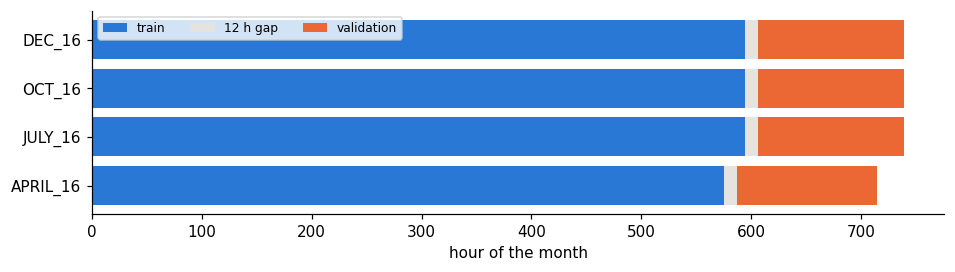

In [7]:
months, static = S.load_months(v4_stats)
train = S.PM25Windows(months, static, v4_stats, 'train')
val = S.PM25Windows(months, static, v4_stats, 'val')
print(f'{len(train)} training windows, {len(val)} validation windows')

fig, ax = plt.subplots(figsize=(10, 2.4))
for k, m in enumerate(C.MONTHS):
    T = months[m]['T']
    vb = S.month_val_start(T)
    ax.barh(k, vb - C.GAP, color='#2a78d6', label='train' if k == 0 else None)
    ax.barh(k, C.GAP, left=vb - C.GAP, color='#e4e3df', label='12 h gap' if k == 0 else None)
    ax.barh(k, T - vb, left=vb, color='#eb6834', label='validation' if k == 0 else None)
ax.set_yticks(range(4)); ax.set_yticklabels(C.MONTHS); ax.set_xlabel('hour of the month'); ax.legend(fontsize=8, ncol=3)
ax.grid(False); plt.show()

The last training window ends its targets before the gap, so no validation hour is ever a training
target. The validation windows above printed how often the estimated start hour is within one hour of
the truth.

## 5. Hour estimation

The test windows carry no timestamps. The start hour of a window is estimated by matching its mean
shortwave radiation and temperature to hourly templates from training; validation uses the estimate
exactly as the test does.

In [8]:
est = val.est_hours
true = np.array([s_ % 24 for _, s_ in val.samples])
err = np.minimum((est - true) % 24, (true - est) % 24)
print(f'start hour exact for {100 * (err == 0).mean():.1f}% of validation windows, within one hour for {100 * (err <= 1).mean():.1f}%')

start hour exact for 60.7% of validation windows, within one hour for 97.7%


## 6. The network input

In [9]:
x, t_log, t_raw, last_log, mask = val[0]
names = C.FEATS + ['wind speed', 'ventilation', 'advection', 'tendency', 'hour sin', 'hour cos', 'diurnal anomaly',
                   'latitude', 'longitude', 'PM2.5 climatology', 'STL residual spread']
print('input', tuple(x.shape), '(channels, hours, rows, columns); target', tuple(t_raw.shape))
for k, n in enumerate(names):
    print(f'{k:2d} {n:22s} mean {float(x[k].mean()):+.2f}  sd {float(x[k].std()):.2f}')

input (20, 10, 140, 124) (channels, hours, rows, columns); target (16, 140, 124)
 0 cpm25                  mean -0.01  sd 1.12
 1 q2                     mean -0.30  sd 0.85
 2 t2                     mean +0.33  sd 0.90
 3 u10                    mean +0.01  sd 0.79
 4 v10                    mean +0.02  sd 0.91
 5 pblh                   mean +0.14  sd 1.27
 6 psfc                   mean -0.37  sd 0.53
 7 swdown                 mean -0.55  sd 0.40
 8 rain                   mean -0.18  sd 0.23
 9 wind speed             mean -0.14  sd 0.88
10 ventilation            mean -0.04  sd 1.04
11 advection              mean -0.10  sd 0.89
12 tendency               mean +0.17  sd 0.84
13 hour sin               mean -0.45  sd 0.52
14 hour cos               mean -0.59  sd 0.42
15 diurnal anomaly        mean -0.02  sd 1.12
16 latitude               mean +0.04  sd 0.58
17 longitude              mean -0.00  sd 0.58
18 PM2.5 climatology      mean -0.00  sd 1.00
19 STL residual spread    mean -0.00  sd 1.00